# 05 — Detection: localise the animal, measure mAP and IoU

Project 11 requires mAP and IoU, and the species corpus (iWildCam v2.0) carries **no bounding boxes at all**, so localisation trains on a second camera-trap dataset: `ankanghosh651/object-detection-wildlife-dataset-yolo-format` (Kaggle, license reported by the API as MIT, 471 MB, 4 classes: buffalo, elephant, rhino, zebra). The corpus switch is declared in `docs/SOURCE_LOG.md` row 2.

Elephant and buffalo are the species that actually damage crops and endanger people, so this is the conflict half of the product, not an unrelated dataset. The second architecture the compendium asks for (Faster R-CNN on the same labels) follows in notebook 06; Phase I reports one detector with honest numbers rather than two half-working ones.

In [1]:
import json, os, time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from ultralytics import YOLO

ROOT = next(a for a in [Path.cwd(), *Path.cwd().parents] if (a / "data/splits").exists())
DETECT = ROOT / "data/raw/_yolo/final_data"
OUT = Path(os.environ.get("P11_OUT", ROOT / "outputs/logs/notebook05"))
OUT.mkdir(parents=True, exist_ok=True)
SEED = 13
EPOCHS = int(os.environ.get("P11_EPOCHS", 50))
IMGSZ = int(os.environ.get("P11_IMGSZ", 640))
BATCH = int(os.environ.get("P11_BATCH", 8))
assert DETECT.is_dir(), f"missing detection dataset at {DETECT}"
print(json.dumps({"ultralytics": ultralytics.__version__, "torch": torch.__version__,
                  "cuda": torch.cuda.is_available(),
                  "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
                  "dataset": str(DETECT), "epochs": EPOCHS, "imgsz": IMGSZ, "batch": BATCH,
                  "out": str(OUT)}, indent=2))

{
  "ultralytics": "8.4.184",
  "torch": "2.7.1+cu118",
  "cuda": true,
  "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU",
  "dataset": "C:\\Users\\xxshi\\Desktop\\PYTHOM\\DL_PBL\\data\\raw\\_yolo\\final_data",
  "epochs": 50,
  "imgsz": 640,
  "batch": 8,
  "out": "C:\\Users\\xxshi\\Desktop\\PYTHOM\\DL_PBL\\outputs\\logs\\notebook05"
}


## 1. Audit before training

Images and label files must pair up, and the class distribution decides whether mAP is meaningful. This set has no `empty` class, which is exactly why the false-alert metric cannot be measured here - that metric stays on the species corpus.

In [2]:
CLASSES = {0: "buffalo", 1: "elephant", 2: "rhino", 3: "zebra"}
splits = {}
for s in ("train", "valid", "test"):
    imgs = sorted((DETECT / s / "images").glob("*.*"))
    lbls = sorted((DETECT / s / "labels").glob("*.txt"))
    counts = Counter()
    boxes = []
    bad_lines = 0
    for p in lbls:
        for line in p.read_text(encoding="utf-8").strip().splitlines():
            parts = line.split()
            if len(parts) != 5:
                bad_lines += 1
                continue
            counts[CLASSES[int(parts[0])]] += 1
            boxes.append((float(parts[3]), float(parts[4])))
    splits[s] = {"images": len(imgs), "labels": len(lbls),
                 "unpaired_stems": len({p.stem for p in imgs} ^ {p.stem for p in lbls}),
                 "malformed_lines": bad_lines, "boxes": int(sum(counts.values())),
                 "per_class": dict(counts)}
    if s == "train" and boxes:
        bw, bh = zip(*boxes)
        smallest = min(counts, key=counts.get)
        print(f"train boxes: median width {np.median(bw):.3f}, median height {np.median(bh):.3f} "
              f"(normalised fractions); smallest class {smallest} with {counts[smallest]} boxes")
pd.DataFrame(splits).T.drop(columns=["per_class"])

train boxes: median width 0.384, median height 0.541 (normalised fractions); smallest class rhino with 445 boxes


,images,labels,unpaired_stems,malformed_lines,boxes
train,1203,1203,0,0,2157
valid,150,150,0,0,262
test,151,151,0,0,266


buffalo     447
zebra       662
elephant    603
rhino       445


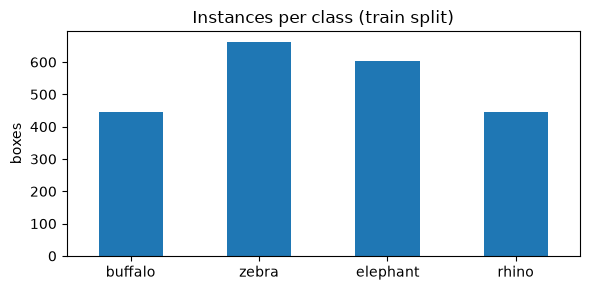

In [3]:
train_counts = pd.Series(splits["train"]["per_class"])
ax = train_counts.plot.bar(figsize=(6, 3), rot=0, title="Instances per class (train split)")
ax.set_ylabel("boxes")
plt.tight_layout()
print(train_counts.to_string())

In [4]:
yaml_path = DETECT / "wildlife_local.yaml"
names_block = "".join(f"  {i}: {n}" + chr(10) for i, n in CLASSES.items())
yaml_path.write_text("path: " + DETECT.as_posix() + chr(10)
                     + "train: train/images" + chr(10) + "val: valid/images" + chr(10)
                     + "test: test/images" + chr(10) + "names:" + chr(10) + names_block,
                     encoding="utf-8")
print(yaml_path.read_text(encoding="utf-8"))

path: C:/Users/xxshi/Desktop/PYTHOM/DL_PBL/data/raw/_yolo/final_data
train: train/images
val: valid/images
test: test/images
names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra



## 1b. Duplicate audit and de-leaked split lists

Byte-level hashing found this dataset leaking: some `valid`/`test` images are identical to `train`
images. Measuring mAP on those copies measures memorisation, not detection, so the audit is reported and
the evaluation is repeated on deduplicated lists (a copy is kept only in the earliest split, and a
16x16 average hash flags near-duplicates that a byte hash misses).

In [5]:
import hashlib

SPLIT_ORDER = ("train", "valid", "test")


def ahash(path, size=16):
    from PIL import Image
    gray = Image.open(path).convert("L").resize((size, size))
    px = np.asarray(gray, dtype=np.float32)
    bits = (px > px.mean()).flatten()
    value = 0
    for b in bits.astype(np.uint8):
        value = (value << 1) | int(b)
    return value


def hamming(a, b):
    return bin(a ^ b).count("1")


exact, near = {}, {}
for s in SPLIT_ORDER:
    for p in sorted((DETECT / s / "images").glob("*.*")):
        exact.setdefault(hashlib.md5(p.read_bytes()).hexdigest(), []).append((s, p.name))
        near.setdefault(ahash(p), []).append((s, p.name))

dup_groups = [v for v in exact.values() if len(v) > 1]
cross = [(k, v) for k, v in exact.items() if len({s for s, _ in v}) > 1]
print(f"byte-identical groups: {len(dup_groups)} (extra copies {sum(len(v) - 1 for v in dup_groups)})")
print(f"groups spanning more than one split: {len(cross)}")
for k, v in cross[:6]:
    print("   ", v)

near_cross = 0
keys = sorted(near)
for i, a in enumerate(keys):
    for b in keys[i + 1:]:
        if hamming(a, b) <= 4 and {s for s, _ in near[a]} != {s for s, _ in near[b]}:
            near_cross += 1
print(f"near-duplicate (hamming<=4) pairs across splits: {near_cross}")

keep = {}
for h, items in exact.items():
    for j, key in enumerate(items):
        keep[key] = (j == 0)
lists = {s: [] for s in SPLIT_ORDER}
dropped = Counter()
for (s, name), is_first in keep.items():
    (lists[s].append(name) if is_first else dropped.update([s]))
for s in SPLIT_ORDER:
    print(f"{s}: {len(lists[s])} kept, {dropped[s]} duplicate copies dropped")

# Ultralytics resolves list files against stale label caches, so the de-leaked split is materialised as
# real folders with their label files, and stale caches are removed before anything trains on it.
import shutil
DEDUP_ROOT = DETECT.parent / "final_data_dedup"
if DEDUP_ROOT.exists():
    shutil.rmtree(DEDUP_ROOT)
for s in SPLIT_ORDER:
    for sub in ("images", "labels"):
        (DEDUP_ROOT / s / sub).mkdir(parents=True, exist_ok=True)
    for name in lists[s]:
        shutil.copy2(DETECT / s / "images" / name, DEDUP_ROOT / s / "images" / name)
        stem = Path(name).stem
        lbl = DETECT / s / "labels" / f"{stem}.txt"
        if lbl.is_file():
            shutil.copy2(lbl, DEDUP_ROOT / s / "labels" / f"{stem}.txt")
for cache in DETECT.rglob("*.cache"):
    cache.unlink()

after = {}
for s in SPLIT_ORDER:
    for p in sorted((DEDUP_ROOT / s / "images").glob("*.*")):
        after.setdefault(hashlib.md5(p.read_bytes()).hexdigest(), set()).add(s)
still_cross = sum(1 for v in after.values() if len(v) > 1)
total_kept = sum(len(lists[s]) for s in SPLIT_ORDER)
print("images in deduplicated tree:", sum(len(list((DEDUP_ROOT / s / 'images').glob('*.*'))) for s in SPLIT_ORDER))
assert total_kept == len(exact), (total_kept, len(exact))
assert still_cross == 0, f"{still_cross} duplicate groups still span splits"
assert all((DEDUP_ROOT / s / 'labels' / f'{Path(n).stem}.txt').exists() for s in SPLIT_ORDER for n in lists[s]),     "an image was copied without its label file"
print("verification: every unique image kept exactly once, no split overlap, every label present")

dedup_yaml = DEDUP_ROOT / "wildlife_local_dedup.yaml"
dedup_yaml.write_text("path: " + DEDUP_ROOT.as_posix() + chr(10)
                      + "train: train/images" + chr(10) + "val: valid/images" + chr(10)
                      + "test: test/images" + chr(10) + "names:" + chr(10) + names_block,
                      encoding="utf-8")
print(dedup_yaml.read_text(encoding="utf-8"))
print("note: only byte-identical copies are removed; the near-duplicate count above is reported, not filtered")

byte-identical groups: 40 (extra copies 41)
groups spanning more than one split: 17
    [('train', '0098.jpg'), ('test', '0334.jpg')]
    [('train', '0124.jpg'), ('test', '0122.jpg')]
    [('train', '0316.jpg'), ('valid', '0067.jpg')]
    [('train', '0327.jpg'), ('valid', '0015.jpg')]
    [('train', '0339.jpg'), ('test', '0033.jpg')]
    [('train', '0759.jpg'), ('test', '1039.jpg')]


near-duplicate (hamming<=4) pairs across splits: 6
train: 1180 kept, 23 duplicate copies dropped
valid: 144 kept, 6 duplicate copies dropped
test: 139 kept, 12 duplicate copies dropped


images in deduplicated tree: 1463
verification: every unique image kept exactly once, no split overlap, every label present
path: C:/Users/xxshi/Desktop/PYTHOM/DL_PBL/data/raw/_yolo/final_data_dedup
train: train/images
val: valid/images
test: test/images
names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra

note: only byte-identical copies are removed; the near-duplicate count above is reported, not filtered


## 2. Train YOLOv8n

Nano backbone at 640 px, batch 8 - the configuration a 6 GB laptop GPU can actually run, which is the deployment constraint the product claims to meet. COCO-pretrained weights are fine-tuned here and declared in the source log.

In [6]:
t0 = time.time()
CKPT = os.environ.get("P11_CKPT", "")
if CKPT and Path(CKPT).is_file():
    model = YOLO(CKPT)
    train_sec = None
    print("loaded trained checkpoint " + CKPT + " - training skipped for this pass")
else:
    model = YOLO("yolov8n.pt")
    res = model.train(data=str(dedup_yaml), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED,
                      project=str(OUT.parent), name="yolo_runs_dedup", exist_ok=True, plots=True,
                      verbose=False)
    train_sec = round(time.time() - t0, 1)
print("train seconds", train_sec, "| trained on deduplicated train list")

Ultralytics 8.4.184  Python-3.11.9 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\_yolo\final_data_dedup\wildlife_local_dedup.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_runs_dedup, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, ov

Overriding model.yaml nc=80 with nc=4



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (5,937 outputs left out)

                   all        144        256      0.967      0.924      0.975      0.856


Speed: 0.5ms preprocess, 2.2ms inference, 0.0ms loss, 2.3ms postprocess per image


Results saved to C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\outputs\logs\yolo_runs_dedup


train seconds 984.5 | trained on deduplicated train list


In [7]:
metrics = model.val(data=str(yaml_path), split="test", imgsz=IMGSZ, batch=BATCH, verbose=False)
summary = {"mAP50": float(metrics.box.map50), "mAP50_95": float(metrics.box.map),
           "precision": float(metrics.box.mp), "recall": float(metrics.box.mr)}
metrics_dd = model.val(data=str(dedup_yaml), split="test", imgsz=IMGSZ, batch=BATCH, verbose=False)
dedup_summary = {"mAP50": float(metrics_dd.box.map50), "mAP50_95": float(metrics_dd.box.map),
                 "precision": float(metrics_dd.box.mp), "recall": float(metrics_dd.box.mr)}
print(json.dumps({"test_as_shipped": {k: round(v, 4) for k, v in summary.items()},
                  "test_deduplicated": {k: round(v, 4) for k, v in dedup_summary.items()},
                  "delta_from_removing_duplicates": {k: round(dedup_summary[k] - summary[k], 4)
                                                     for k in summary}}, indent=2))
ap_index = getattr(metrics_dd.box, "ap_class_index", None)
idx = list(range(len(CLASSES))) if ap_index is None or len(ap_index) == 0 else [int(i) for i in ap_index]
per_class = pd.DataFrame({"class": [CLASSES[i] for i in idx],
                          "AP50_dedup": [round(float(metrics_dd.box.ap50[i]), 4) for i in idx],
                          "AP50_95_dedup": [round(float(metrics_dd.box.ap[i]), 4) for i in idx],
                          "AP50_as_shipped": [round(float(metrics.box.ap50[i]), 4) for i in idx]})
per_class

Ultralytics 8.4.184  Python-3.11.9 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)


Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access  (ping: 0.2±0.2 ms, read: 144.8±50.6 MB/s, size: 160.5 KB)


val: Scanning C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\_yolo\final_data\test\labels... 125 images, 0 backgrounds, 0 corrupt: 82% ━━━━━━━━━╸── 125/151 369.5it/s 0.1s<0.1s

val: Scanning C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\_yolo\final_data\test\labels... 151 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 151/151 1.2Kit/s 0.1s

val: New cache created: C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\_yolo\final_data\test\labels.cache


... (30 outputs left out)

Speed: 1.0ms preprocess, 4.3ms inference, 0.0ms loss, 1.7ms postprocess per image


Results saved to C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\notebooks\runs\detect\val-4


{
  "test_as_shipped": {
    "mAP50": 0.9487,
    "mAP50_95": 0.7981,
    "precision": 0.919,
    "recall": 0.9194
  },
  "test_deduplicated": {
    "mAP50": 0.9469,
    "mAP50_95": 0.794,
    "precision": 0.9125,
    "recall": 0.9144
  },
  "delta_from_removing_duplicates": {
    "mAP50": -0.0019,
    "mAP50_95": -0.0042,
    "precision": -0.0065,
    "recall": -0.0049
  }
}


,class,AP50_dedup,AP50_95_dedup,AP50_as_shipped
0,buffalo,0.9493,0.8018,0.9525
1,elephant,0.9384,0.7607,0.9382
2,rhino,0.9421,0.8177,0.9425
3,zebra,0.9577,0.7957,0.9617


## 3. Latency and memory — the edge constraint

Measured after warm-up on the GPU that trained the model, with peak memory from the CUDA allocator. This is a proxy for field power use and is labelled as a proxy: no camera-trap board was available.

In [8]:
imgs = sorted((DETECT / "test" / "images").glob("*.*"))[:100]
_ = model.predict(str(imgs[0]), imgsz=IMGSZ, verbose=False)
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
dets = 0
for p in imgs:
    r = model.predict(str(p), imgsz=IMGSZ, conf=0.25, verbose=False)[0]
    dets += len(r.boxes)
lat_ms = round((time.time() - t0) / len(imgs) * 1000, 1)
peak_mb = round(torch.cuda.max_memory_allocated() / 2**20, 1) if torch.cuda.is_available() else None
print(json.dumps({"images_timed": len(imgs), "ms_per_frame": lat_ms, "fps": round(1000 / lat_ms, 2),
                  "peak_gpu_mb": peak_mb, "avg_detections_per_frame": round(dets / len(imgs), 2)}, indent=2))

{
  "images_timed": 100,
  "ms_per_frame": 26.8,
  "fps": 37.31,
  "peak_gpu_mb": 149.4,
  "avg_detections_per_frame": 1.53
}


saved C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\outputs\logs\notebook05\detections_examples.png


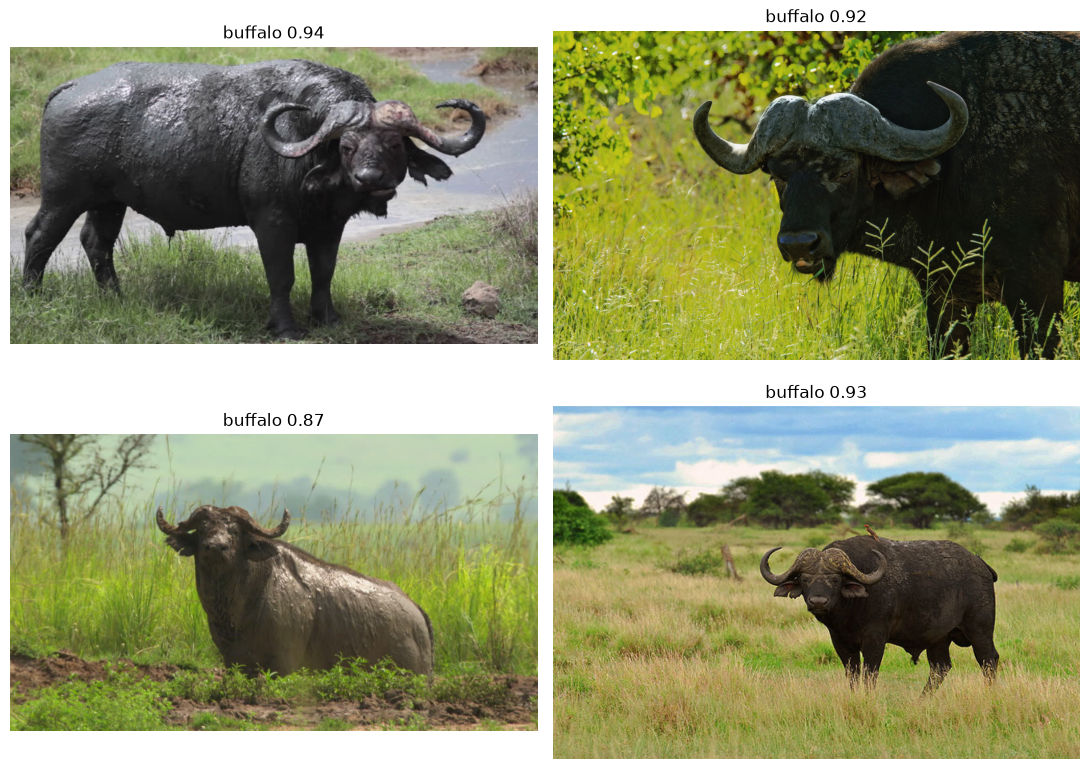

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, p in zip(axes.ravel(), imgs[:4]):
    r = model.predict(str(p), imgsz=IMGSZ, conf=0.35, verbose=False)[0]
    ax.imshow(np.asarray(r.orig_img[..., ::-1]))
    labels = ", ".join(f"{CLASSES[int(b.cls)]} {float(b.conf):.2f}" for b in r.boxes) or "no detection"
    ax.set_title(labels)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT / "detections_examples.png", dpi=110)
print("saved", OUT / "detections_examples.png")

In [10]:
run = {"run_utc": pd.Timestamp.now(tz="UTC").isoformat(), "experiment": "notebook05_yolov8n_detection",
       "seed": SEED, "dataset": "ankanghosh651/object-detection-wildlife-dataset-yolo-format",
       "classes": list(CLASSES.values()),
       "split_audit": {s: {k: v for k, v in d.items() if k != "per_class"} for s, d in splits.items()},
       "model": "yolov8n.pt (COCO pretrained, fine-tuned)", "epochs": EPOCHS, "imgsz": IMGSZ,
       "batch": BATCH, "train_sec": train_sec,
       "test": {k: round(v, 4) for k, v in summary.items()},
       "test_deduplicated": {k: round(v, 4) for k, v in dedup_summary.items()},
       "per_class": per_class.to_dict("records"),
       "ms_per_frame": lat_ms, "fps": round(1000 / lat_ms, 2), "peak_gpu_mb": peak_mb,
       "ultralytics": ultralytics.__version__,
       "hardware": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"}
with open(OUT / "experiment_log.jsonl", "a", encoding="utf-8") as fh:
    fh.write(json.dumps(run) + chr(10))
print(json.dumps({k: run[k] for k in ("test", "ms_per_frame", "peak_gpu_mb")}, indent=2))

{
  "test": {
    "mAP50": 0.9487,
    "mAP50_95": 0.7981,
    "precision": 0.919,
    "recall": 0.9194
  },
  "ms_per_frame": 26.8,
  "peak_gpu_mb": 149.4
}


## 4. What these numbers do and do not support

* **The shipped split leaks.** Byte hashing found exact copies of train images inside `valid` and `test` (see 1b), so the as-shipped mAP is measured partly on memorised images. Both numbers are printed; the deduplicated one is the one to quote.
* mAP and IoU are measured on a **different corpus** from the species classifier (4 African species, no empty frames). Any sentence that merges the two must say so: alert metrics come from iWildCam, detection metrics from here.
* ~1.2k train images and 4 classes is small, so per-class AP matters more than the mean and the smallest class (rhino, 445 boxes) drives the error bars.
* Latency and peak memory are the edge-deployment proxy. Real power draw on a camera-trap board was not measurable here and is not claimed.
* Next for the compendium's two-architecture benchmark: torchvision Faster R-CNN (ResNet-FPN) on the same labels after converting YOLO txt to COCO, at equal epochs, the same seed, and the same deduplicated lists.